# 06 — Variantes da CNN e da RNN com 5 seeds

O notebook 05 fixou o protocolo:
- pesos de classe **iguais aos da métrica** (5/3/1);
- regra de agregação **`mean`** (média das probabilidades das gravações do paciente);
- época escolhida pela **menor loss da validação** (paciência 8);
- **WA justa**: a época é escolhida numa metade dos pacientes da validação e a WA é medida na outra
  (20 divisões estratificadas, média);
- 5 seeds por configuração, média ± desvio.

Aqui usa-se esse protocolo para testar **uma mudança de cada vez** em relação às duas referências
(`cnn_wmetric` e `rnn_wmetric`), todas com os pesos da métrica:

| Experiência | Mudança | Hipótese |
|---|---|---|
| `cnn_specaug` | SpecAugment no treino (2 faixas de frequência ≤ 8 bandas, 2 de tempo ≤ 0.64 s) | a CNN deixa de depender de detalhes concretos e generaliza melhor |
| `cnn_audible` | tirar do treino as janelas de pacientes *Present* sem sopro audível naquele local (351 de 2 148) | essas janelas ensinam a rede a chamar *Present* a sons normais |
| `rnn_lstm` | LSTM em vez de GRU | a LSTM tem uma "memória" extra (célula), mais parâmetros (141 mil vs. 106 mil) |
| `rnn_delta` | MFCC + deltas de 1.ª e 2.ª ordem (13 → 39 features por instante) | a variação no tempo dos coeficientes ajuda a separar sopro de som normal |
| `rnn_mel` | a GRU lê o log-mel (64 bandas) em vez dos 13 MFCC | o MFCC resume o espectro; as 64 bandas guardam mais detalhe |
| `rnn_h128` | 128 unidades por direção em vez de 64 (408 mil parâmetros) | mais capacidade (ou mais *overfitting*) |
| `rnn_audible` | o mesmo filtro do `cnn_audible`, na RNN | idem |

Seeds 42, 1, 2, 3, 4; 40 épocas fixas; tudo o resto como nos notebooks 03/04 (Adam lr 1e-3, wd 1e-4, batch 64).
O treino está em `src/run_seeds.py` (saída em `runs/`, fora do git).
**O teste continua a não ser usado.**

In [1]:
import sys; sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold

from src.data import ROOT
from src.metrics import CLASSES, WEIGHTS, confusion_matrix, weighted_accuracy
from src.features import load_features
from src.models import count_parameters
from src.training import RULES, class_weights, patient_predictions, CLASS_INDEX
from src.run_seeds import EXPERIMENTS, SEEDS, build_model

sns.set_theme(style="whitegrid")
RUNS, RESULTS = ROOT / "runs", ROOT / "results"
meta_val = pd.read_csv(RUNS / "meta_val.csv")
meta_train = load_features("train", "mel")[1]
CNN = ["cnn_wmetric", "cnn_specaug", "cnn_audible"]
RNN = ["rnn_wmetric", "rnn_lstm", "rnn_delta", "rnn_mel", "rnn_h128", "rnn_audible"]
EXPS = CNN + RNN
REF = {"cnn": "cnn_wmetric", "rnn": "rnn_wmetric"}
print(len(meta_val), "janelas de validação,", meta_val["patient_id"].nunique(), "pacientes")

2431 janelas de validação, 142 pacientes


## 1. Previsões por paciente em todas as épocas

Como no notebook 05: para cada experiência, seed, época e regra, a previsão de cada paciente da validação;
e a loss de cada paciente (soma nas suas janelas), para escolher a época num subconjunto de pacientes.

In [2]:
y_win = meta_val["murmur"].map(CLASS_INDEX).to_numpy()
w_win = class_weights(meta_train, "metric").numpy()[y_win]
rows, losses, histories, probs_all = [], [], {}, {}
for exp in EXPS:
    for seed in SEEDS:
        probs = np.load(RUNS / exp / f"seed{seed}" / "val_probs.npy").astype(np.float32)
        probs_all[exp, seed] = probs
        histories[exp, seed] = pd.read_csv(RUNS / exp / f"seed{seed}" / "history.csv")
        for epoch, p in enumerate(probs, start=1):
            for rule in RULES:
                rows.append(patient_predictions(meta_val, p, rule).assign(exp=exp, seed=seed, epoch=epoch, rule=rule))
            nll = -np.log(p[np.arange(len(p)), y_win] + 1e-8)
            losses.append(pd.DataFrame({"patient_id": meta_val["patient_id"], "wl": w_win * nll, "w": w_win})
                          .groupby("patient_id").sum().reset_index().assign(exp=exp, seed=seed, epoch=epoch))
preds = pd.concat(rows, ignore_index=True)
preds["weight"] = preds["murmur"].map(WEIGHTS)
preds["hit"] = (preds["murmur"] == preds["pred"]) * preds["weight"]
losses = pd.concat(losses, ignore_index=True)
patients = preds[["patient_id", "murmur"]].drop_duplicates().reset_index(drop=True)

def wa_by_epoch(subset=None):
    df = preds if subset is None else preds[preds["patient_id"].isin(subset)]
    g = df.groupby(["exp", "seed", "rule", "epoch"])[["hit", "weight"]].sum()
    return (g["hit"] / g["weight"]).rename("wa")

def loss_by_epoch(subset=None):
    df = losses if subset is None else losses[losses["patient_id"].isin(subset)]
    g = df.groupby(["exp", "seed", "epoch"])[["wl", "w"]].sum()
    return (g["wl"] / g["w"]).rename("loss")

curves = wa_by_epoch().reset_index()
val_loss = loss_by_epoch().reset_index()

info = pd.DataFrame({exp: {"parâmetros": count_parameters(build_model(EXPERIMENTS[exp])),
                           "min por corrida": round(np.mean([histories[exp, s]["seconds"].sum() for s in SEEDS]) / 60, 1)}
                     for exp in EXPS}).T
info

,parâmetros,min por corrida
cnn_wmetric,98019.0,2.2
cnn_specaug,98019.0,2.4
cnn_audible,98019.0,7.0
rnn_wmetric,105603.0,0.7
rnn_lstm,140547.0,0.7
rnn_delta,115587.0,0.7
rnn_mel,125187.0,0.8
rnn_h128,407811.0,1.6
rnn_audible,105603.0,0.7


## 2. Curvas

Média das 5 seeds (linha) e mínimo–máximo (sombra). Regra `mean`.

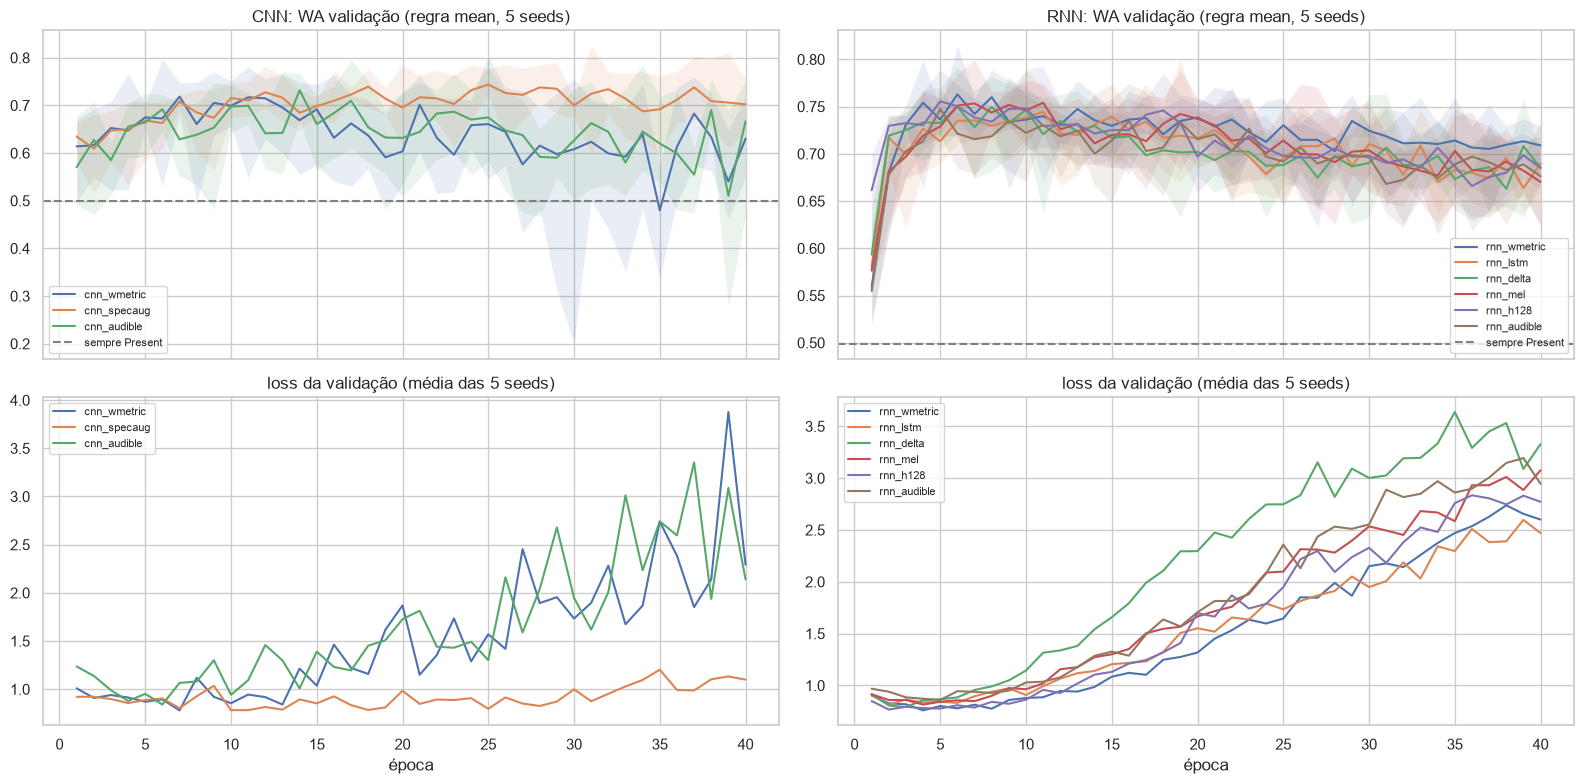

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True)
for col, group in enumerate([CNN, RNN]):
    for exp in group:
        c = curves[(curves["exp"] == exp) & (curves["rule"] == "mean")].groupby("epoch")["wa"]
        axes[0, col].plot(c.mean().index, c.mean(), label=exp)
        axes[0, col].fill_between(c.mean().index, c.min(), c.max(), alpha=0.12)
        l = val_loss[val_loss["exp"] == exp].groupby("epoch")["loss"].mean()
        axes[1, col].plot(l.index, l, label=exp)
    axes[0, col].axhline(0.499, color="gray", ls="--", label="sempre Present")
    axes[0, col].set_title(f"{'CNN' if col == 0 else 'RNN'}: WA validação (regra mean, 5 seeds)")
    axes[1, col].set_title("loss da validação (média das 5 seeds)"); axes[1, col].set_xlabel("época")
    axes[0, col].legend(fontsize=8); axes[1, col].legend(fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS / "variantes_curvas.png", dpi=120); plt.show()

## 3. Avaliação justa

Como no notebook 05: época escolhida numa metade dos pacientes da validação, WA medida na outra, 20 divisões.
A tabela principal usa a configuração comum (`mean` + `es_loss`); as outras combinações aparecem a seguir só para
ver se a conclusão depende delas.

In [4]:
def es_select(scores, patience=8):
    best, best_epoch = -np.inf, None
    for epoch, s in enumerate(scores, start=1):
        if s > best:
            best, best_epoch = s, epoch
        elif epoch - best_epoch >= patience:
            break
    return best_epoch

CRITERIA = ["es_wa", "es_loss"]

def evaluate(sel_patients, eval_patients):
    wa_sel, wa_eval = wa_by_epoch(sel_patients), wa_by_epoch(eval_patients)
    loss_sel = loss_by_epoch(sel_patients)
    out = []
    for (exp, seed, rule), s in wa_sel.groupby(level=["exp", "seed", "rule"]):
        s = s.droplevel(["exp", "seed", "rule"]).to_numpy()
        l = -loss_sel.loc[(exp, seed)].to_numpy()
        for crit, scores in [("es_wa", s), ("es_loss", l)]:
            epoch = es_select(scores)
            out.append({"exp": exp, "seed": seed, "rule": rule, "criterion": crit, "epoch": epoch,
                        "wa": wa_eval.loc[(exp, seed, rule, epoch)]})
    return pd.DataFrame(out)

splits = []
for rep in range(20):
    skf = StratifiedKFold(n_splits=2, shuffle=True, random_state=rep)
    for a, b in skf.split(patients, patients["murmur"]):
        splits.append((rep, patients.loc[a, "patient_id"], patients.loc[b, "patient_id"]))

honest = pd.concat([evaluate(a, b).assign(rep=rep) for rep, a, b in splits])
honest = honest.groupby(["exp", "seed", "rule", "criterion"], as_index=False)[["wa", "epoch"]].mean()
naive = evaluate(None, None)

In [5]:
main = honest.query("rule == 'mean' and criterion == 'es_loss'")
g = main.groupby("exp")["wa"]
table = pd.DataFrame({"WA justa (média)": g.mean(), "desvio entre seeds": g.std(), "mín": g.min(), "máx": g.max(),
                      "época média": main.groupby("exp")["epoch"].mean()}).reindex(EXPS)
table["diferença para a referência"] = [table.loc[e, "WA justa (média)"] - table.loc[REF[e[:3]], "WA justa (média)"]
                                        for e in EXPS]
table = table.join(info)
table.round(3).to_csv(RESULTS / "variantes_wa_justa.csv")
table.round(3)

,WA justa (média),desvio entre seeds,mín,máx,época média,diferença para a referência,parâmetros,min por corrida
exp,,,,,,,,
cnn_wmetric,0.744,0.027,0.704,0.768,8.480,0.000,98019.0,2.2
cnn_specaug,0.726,0.013,0.706,0.741,11.605,-0.017,98019.0,2.4
cnn_audible,0.704,0.015,0.687,0.727,6.290,-0.040,98019.0,7.0
rnn_wmetric,0.760,0.023,0.724,0.786,5.150,0.000,105603.0,0.7
rnn_lstm,0.720,0.026,0.687,0.750,3.970,-0.040,140547.0,0.7
rnn_delta,0.732,0.014,0.711,0.745,3.020,-0.029,115587.0,0.7
rnn_mel,0.733,0.056,0.636,0.773,4.765,-0.027,125187.0,0.8
rnn_h128,0.740,0.018,0.713,0.759,4.795,-0.020,407811.0,1.6
rnn_audible,0.735,0.018,0.712,0.756,5.720,-0.025,105603.0,0.7


In [6]:
# Robustez: as outras combinações de regra e critério (média ± desvio das 5 seeds)
g = honest.groupby(["exp", "rule", "criterion"])["wa"]
robust = (g.mean().round(3).astype(str) + " ± " + g.std().round(3).astype(str)).unstack(["rule", "criterion"])
robust.reindex(EXPS)

rule                   any                          half                 \
criterion          es_loss          es_wa        es_loss          es_wa   
exp                                                                       
cnn_wmetric  0.719 ± 0.027  0.707 ± 0.013  0.721 ± 0.027  0.712 ± 0.013   
cnn_specaug  0.717 ± 0.013   0.731 ± 0.02   0.72 ± 0.013  0.735 ± 0.026   
cnn_audible  0.669 ± 0.026  0.713 ± 0.012   0.67 ± 0.026  0.723 ± 0.012   
rnn_wmetric  0.728 ± 0.015  0.768 ± 0.044   0.735 ± 0.02   0.77 ± 0.037   
rnn_lstm     0.705 ± 0.031  0.722 ± 0.013  0.707 ± 0.029   0.73 ± 0.012   
rnn_delta    0.711 ± 0.034  0.721 ± 0.004  0.713 ± 0.039  0.747 ± 0.019   
rnn_mel      0.698 ± 0.043  0.734 ± 0.017  0.711 ± 0.046  0.747 ± 0.006   
rnn_h128      0.72 ± 0.011  0.753 ± 0.012  0.721 ± 0.011  0.759 ± 0.009   
rnn_audible  0.759 ± 0.015  0.751 ± 0.015  0.766 ± 0.018  0.747 ± 0.016   

rule                  mean                 
criterion          es_loss          es_wa  
exp                                        
cnn_wmetric  0.744 ± 0.027  0.729 ± 0.012  
cnn_specaug  0.726 ± 0.013  0.707 ± 0.016  
cnn_audible  0.704 ± 0.015  0.707 ± 0.028  
rnn_wmetric   0.76 ± 0.023  0.753 ± 0.028  
rnn_lstm      0.72 ± 0.026   0.72 ± 0.017  
rnn_delta    0.732 ± 0.014  0.739 ± 0.029  
rnn_mel      0.733 ± 0.056  0.747 ± 0.017  
rnn_h128      0.74 ± 0.018  0.736 ± 0.018  
rnn_audible  0.735 ± 0.018  0.732 ± 0.016

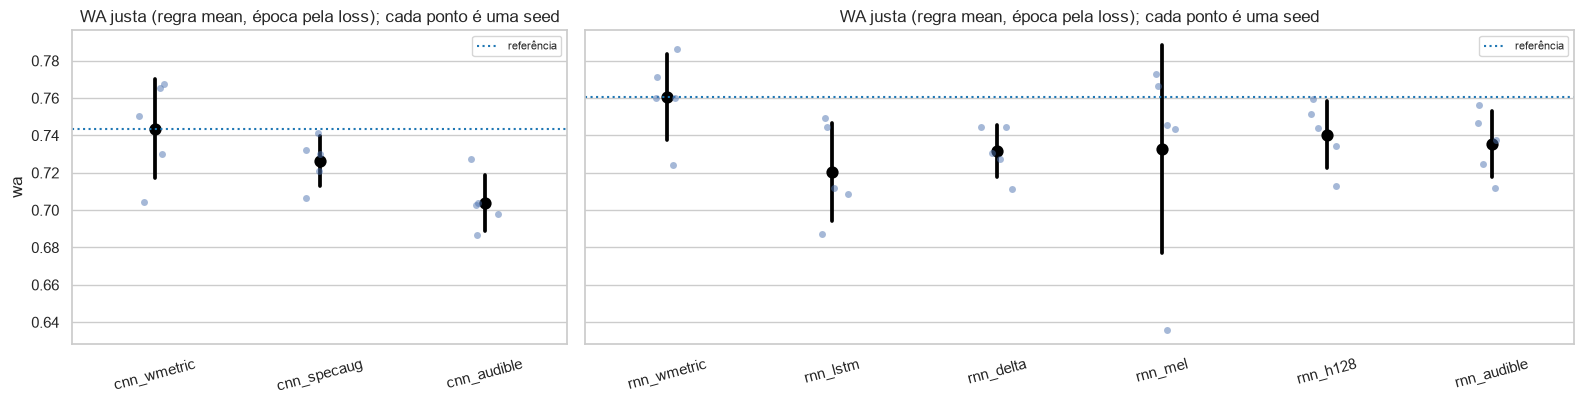

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw={"width_ratios": [len(CNN), len(RNN)]}, sharey=True)
for ax, group in zip(axes, [CNN, RNN]):
    d = main[main["exp"].isin(group)]
    sns.pointplot(d, x="exp", y="wa", order=group, errorbar="sd", linestyle="none", color="black", ax=ax)
    sns.stripplot(d, x="exp", y="wa", order=group, alpha=0.5, ax=ax)
    ax.axhline(table.loc[group[0], "WA justa (média)"], color="tab:blue", ls=":", label="referência")
    ax.set_title("WA justa (regra mean, época pela loss); cada ponto é uma seed"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS / "variantes_wa_justa.png", dpi=120); plt.show()

## 4. Onde estão os erros

Matrizes de confusão por paciente somadas nas 5 seeds (5 × 142 = 710 pacientes), na época escolhida pela loss com
toda a validação. Linhas = previsto, colunas = verdadeiro, como no guião.

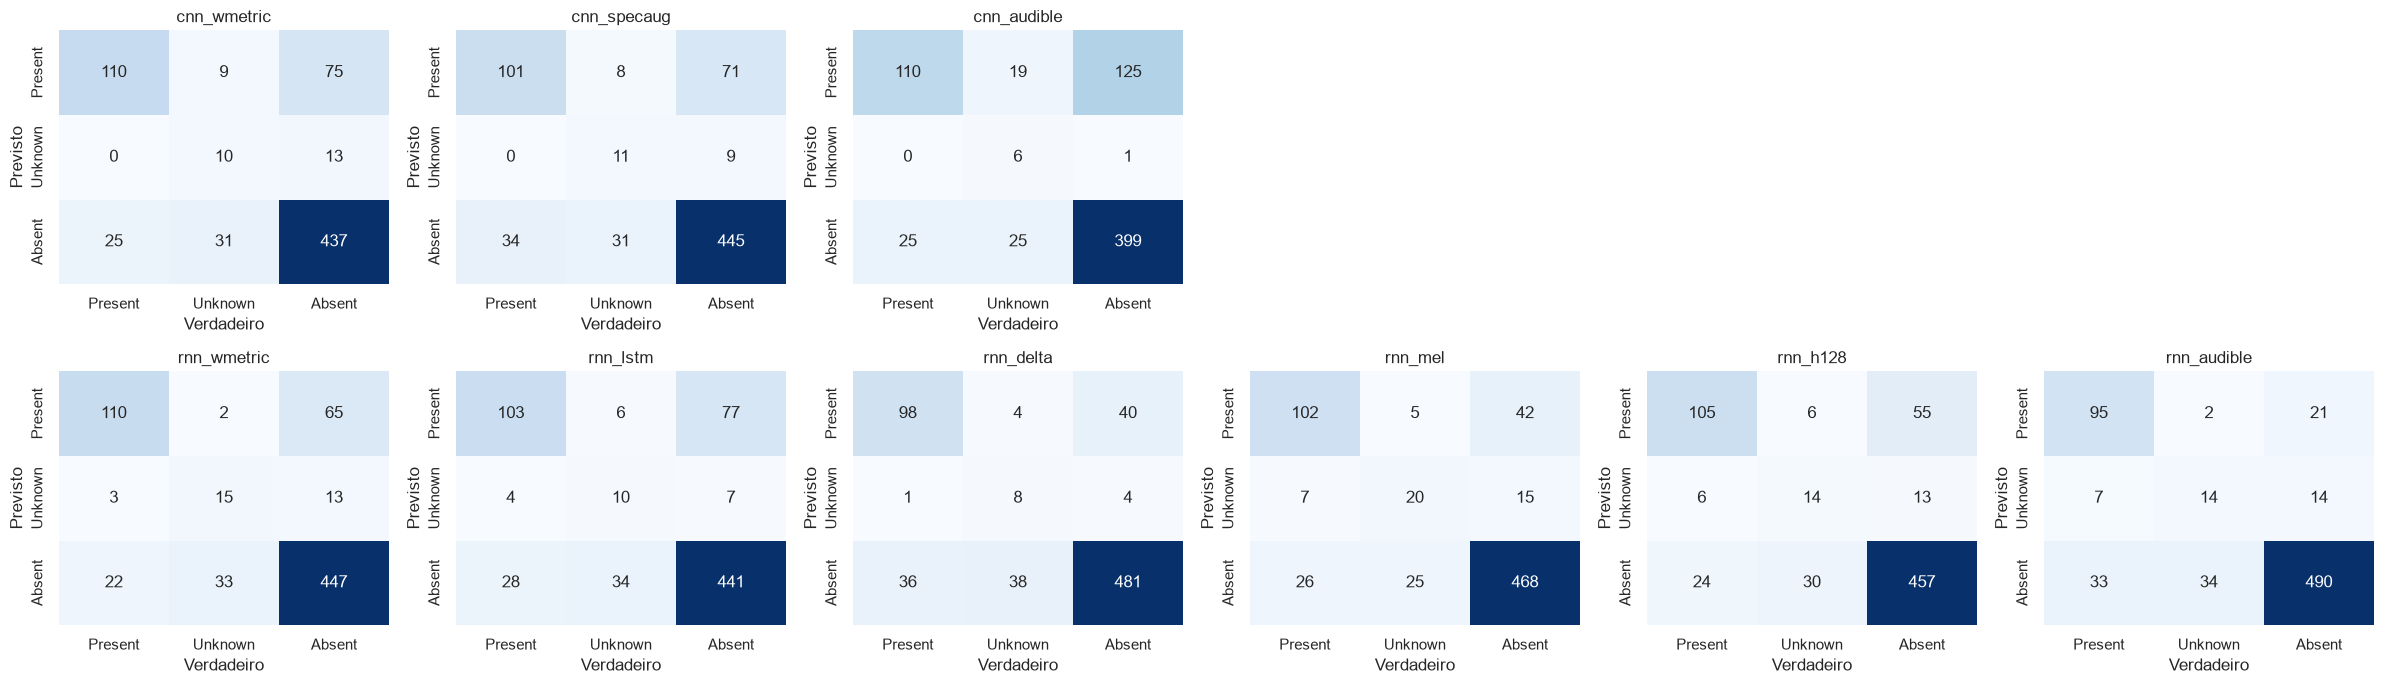

In [8]:
def summed_cm(exp, rule="mean", criterion="es_loss"):
    cm = 0
    for seed in SEEDS:
        epoch = naive.query("exp == @exp and seed == @seed and rule == @rule and criterion == @criterion")["epoch"].item()
        d = preds.query("exp == @exp and seed == @seed and rule == @rule and epoch == @epoch")
        cm = cm + confusion_matrix(d["murmur"], d["pred"])
    return cm

fig, axes = plt.subplots(2, 6, figsize=(24, 7))
for ax in axes.flat:
    ax.axis("off")
for ax, exp in zip(list(axes[0, :len(CNN)]) + list(axes[1, :len(RNN)]), EXPS):
    ax.axis("on")
    sns.heatmap(summed_cm(exp), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(exp)
plt.tight_layout(); plt.savefig(RESULTS / "variantes_matrizes.png", dpi=120); plt.show()

## 5. Ensemble das 5 seeds

Para a pergunta ao professor sobre o bónus: em vez de escolher uma seed, juntar as 5 (média das probabilidades das
janelas, cada seed na sua época escolhida pela loss). Avaliação justa como acima: as épocas são escolhidas na metade
A, a WA do ensemble é medida na metade B.

In [9]:
def ensemble_wa(exp, sel, ev):
    loss_sel = loss_by_epoch(sel)
    p = np.mean([probs_all[exp, s][es_select(-loss_sel.loc[(exp, s)].to_numpy()) - 1] for s in SEEDS], axis=0)
    pp = patient_predictions(meta_val, p, "mean")
    pp = pp[pp["patient_id"].isin(ev)]
    return weighted_accuracy(pp["murmur"], pp["pred"])

ens = pd.DataFrame([{"exp": exp, "rep": rep, "wa": ensemble_wa(exp, a, b)} for exp in EXPS for rep, a, b in splits])
ens = ens.groupby("exp")["wa"].mean().reindex(EXPS)
pd.DataFrame({"média das seeds sozinhas": table["WA justa (média)"], "ensemble das 5 seeds": ens}).round(3)

,média das seeds sozinhas,ensemble das 5 seeds
exp,,
cnn_wmetric,0.744,0.749
cnn_specaug,0.726,0.748
cnn_audible,0.704,0.720
rnn_wmetric,0.760,0.761
rnn_lstm,0.720,0.752
rnn_delta,0.732,0.736
rnn_mel,0.733,0.752
rnn_h128,0.740,0.749
rnn_audible,0.735,0.745


## 6. Conclusões

Execução de **27/11/2026** na GPU (RTX 5060): 7 variantes × 5 seeds × 40 épocas.
Tabelas em `results/variantes_wa_justa.csv`; figuras `results/variantes_*.png`.

**WA justa** (regra `mean`, época pela loss da validação; média ± desvio das 5 seeds):

| Experiência | WA justa | diferença para a referência |
|---|---|---|
| **`cnn_wmetric`** (referência) | **0.744 ± 0.027** | — |
| `cnn_specaug` | 0.726 ± 0.013 | −0.017 |
| `cnn_audible` | 0.704 ± 0.015 | −0.040 |
| **`rnn_wmetric`** (referência, GRU) | **0.760 ± 0.023** | — |
| `rnn_h128` | 0.740 ± 0.018 | −0.020 |
| `rnn_audible` | 0.735 ± 0.018 | −0.025 |
| `rnn_mel` | 0.733 ± 0.056 | −0.027 |
| `rnn_delta` | 0.732 ± 0.014 | −0.029 |
| `rnn_lstm` | 0.720 ± 0.026 | −0.040 |

1. **Nenhuma variante melhorou as referências.** As diferenças vão de −0.02 a −0.04, da ordem de 1 desvio entre
   seeds: não dá para dizer que as variantes são piores, mas nenhuma é melhor. Com outras regras e critérios
   (secção 3) a ordem muda em alguns casos: o `cnn_specaug` (regras `any`/`half` + melhor WA) e o `rnn_audible`
   (regras `any`/`half` + menor loss) passam à frente da referência. Mais uma razão para fixar a configuração antes
   de comparar: escolher a combinação à medida de cada variante seria afinar ao ruído da validação.
2. **SpecAugment acaba com o overfitting da CNN, mas não sobe a WA.** A loss da validação do `cnn_specaug` fica em
   ~0.8–1.1 até à época 40 (na `cnn_wmetric` sobe até 2–4) e a WA oscila muito menos entre épocas e entre seeds
   (desvio 0.013 contra 0.027). Com as regras `any`/`half` e a época pela melhor WA fica à frente (0.731–0.735 contra
   0.707–0.712), mas com a configuração comum fica 0.017 abaixo. Ou seja: torna o treino mais estável, mas não melhora
   o melhor ponto.
3. **O filtro `murmur_audible` muda o tipo de erro, não o total.** Na CNN aumenta os *Absent* dados como *Present*
   (75 → 125 em 525): sem as janelas "Present sem sopro", a rede chama sopro a mais coisas. Na RNN faz o contrário:
   menos *Absent* dados como *Present* (65 → 21), mas perde *Present* (110 → 95 de 135), que valem 5.
4. **RNN: mais entrada ou mais capacidade não ajudam.** Deltas (39 features), log-mel (64 bandas), LSTM ou 128
   unidades ficam todos abaixo da GRU simples sobre 13 MFCC. Todas as RNN atingem a menor loss da validação muito
   cedo (épocas 3–5) e depois a loss sobe sem parar: com ~650 pacientes de treino, o limite é a quantidade de dados,
   não o tamanho do modelo. O `rnn_mel` é o mais instável (uma seed fica em 0.636).
5. **Ensemble das 5 seeds:** quase não muda as referências (CNN 0.744 → 0.749, RNN 0.760 → 0.761) e ajuda sobretudo
   as variantes instáveis (LSTM +0.03, log-mel +0.02). Reduz a variância, não sobe o teto.

**Decisão (configuração final, escolhida só com a validação):**
- **CNN:** `cnn_wmetric` (SmallCNN, log-mel, pesos 5/3/1).
- **RNN:** `rnn_wmetric` (GRU bidirecional 2×64, MFCC, pesos 5/3/1). É o melhor modelo na validação.
- Os dois com regra `mean` e época pela menor loss da validação. No teste reporta-se a média ± desvio das 5 seeds
  (cada uma na sua época) e a matriz de confusão por paciente.
- **O teste continua por usar.**